# Breast Cancer Classification with Scikit-learn

**Question:** Can a simple machine learning model tell malignant from benign breast tumours using measurements taken from cell nuclei in digitised biopsy images?

**Data:** Breast Cancer Wisconsin (Diagnostic) dataset, bundled with scikit-learn (569 samples, 30 numeric features). Originally from the UCI Machine Learning Repository.

**Approach:** Split the data, train two simple models (logistic regression and random forest), compare them with cross-validation on the training set, then evaluate the chosen model once on a held-out test set. I treat *malignant* as the positive class, because missing a malignant case is the more serious error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

RANDOM_STATE = 42

## 1. Load and inspect the data

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

# In scikit-learn's version, target 0 = malignant and 1 = benign.
# I flip it so that 1 = malignant (the positive class we care most about catching).
y = pd.Series(1 - data.target, name="malignant")

print("Samples and features:", X.shape)
print("Missing values:", int(X.isna().sum().sum()))
print()
print("Class counts (1 = malignant, 0 = benign):")
print(y.value_counts().rename({1: "malignant", 0: "benign"}))
print()
print("Share of malignant cases: {:.1%}".format(y.mean()))

Samples and features: (569, 30)
Missing values: 0

Class counts (1 = malignant, 0 = benign):
malignant
benign       357
malignant    212
Name: count, dtype: int64

Share of malignant cases: 37.3%


The classes are moderately imbalanced (more benign than malignant), so accuracy alone can be misleading. I also report precision, recall and F1 for the malignant class.

## 2. Train/test split
I hold out 20% of the data as a test set. The split is *stratified* so both sets keep the same share of malignant cases. The test set is not used for any model choice.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share - train: {:.1%}, test: {:.1%}".format(y_train.mean(), y_test.mean()))

Train: (455, 30)  Test: (114, 30)
Malignant share - train: 37.4%, test: 36.8%


## 3. Compare two models with cross-validation (training data only)
- **Logistic regression** (with feature scaling): a simple, interpretable baseline.
- **Random forest**: a more flexible tree-based model.

Scaling is placed inside a pipeline so it is learned only from each training fold, which avoids data leakage.

In [4]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1"]

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name, **{m: res[f"test_{m}"].mean() for m in scoring}})

cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,accuracy,precision,recall,f1
model,,,,
Logistic regression,0.974,0.977,0.953,0.964
Random forest,0.960,0.958,0.935,0.946


## 4. Final evaluation on the held-out test set
I choose the model with the better cross-validated recall and F1 for the malignant class, fit it on all training data, and evaluate it **once** on the test set.

In [5]:
# Pick the best model using cross-validation results only (not the test set)
best_name = cv_table[["recall", "f1"]].mean(axis=1).idxmax()
print("Selected model:", best_name)

final_model = models[best_name]
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

results = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision (malignant)": precision_score(y_test, y_pred),
    "recall (malignant)": recall_score(y_test, y_pred),
    "f1 (malignant)": f1_score(y_test, y_pred),
}
pd.Series(results).round(3).to_frame("test set score")

Selected model: Logistic regression


,test set score
accuracy,0.965
precision (malignant),0.975
recall (malignant),0.929
f1 (malignant),0.951


In [6]:
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"], digits=3))

              precision    recall  f1-score   support

      benign      0.959     0.986     0.973        72
   malignant      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



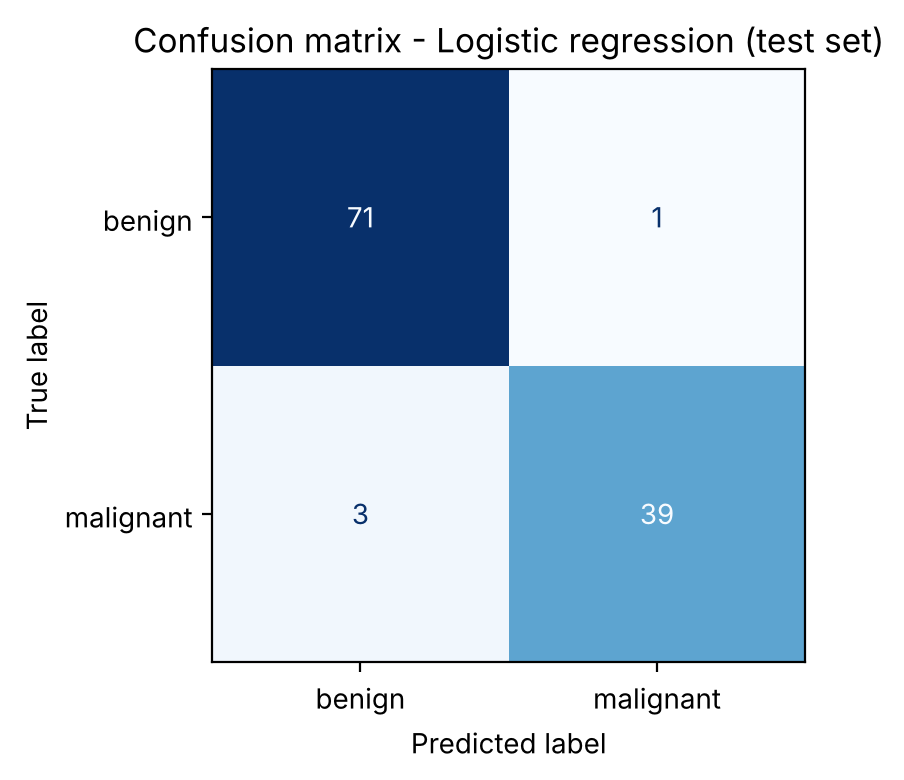

True negatives: 71  False positives: 1  False negatives: 3  True positives: 39


In [7]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Confusion matrix - {best_name} (test set)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives: {tn}  False positives: {fp}  False negatives: {fn}  True positives: {tp}")

## 5. Which features matter most?
This is a quick look at which measurements the selected model relies on. It shows association within this dataset, not biological causation.

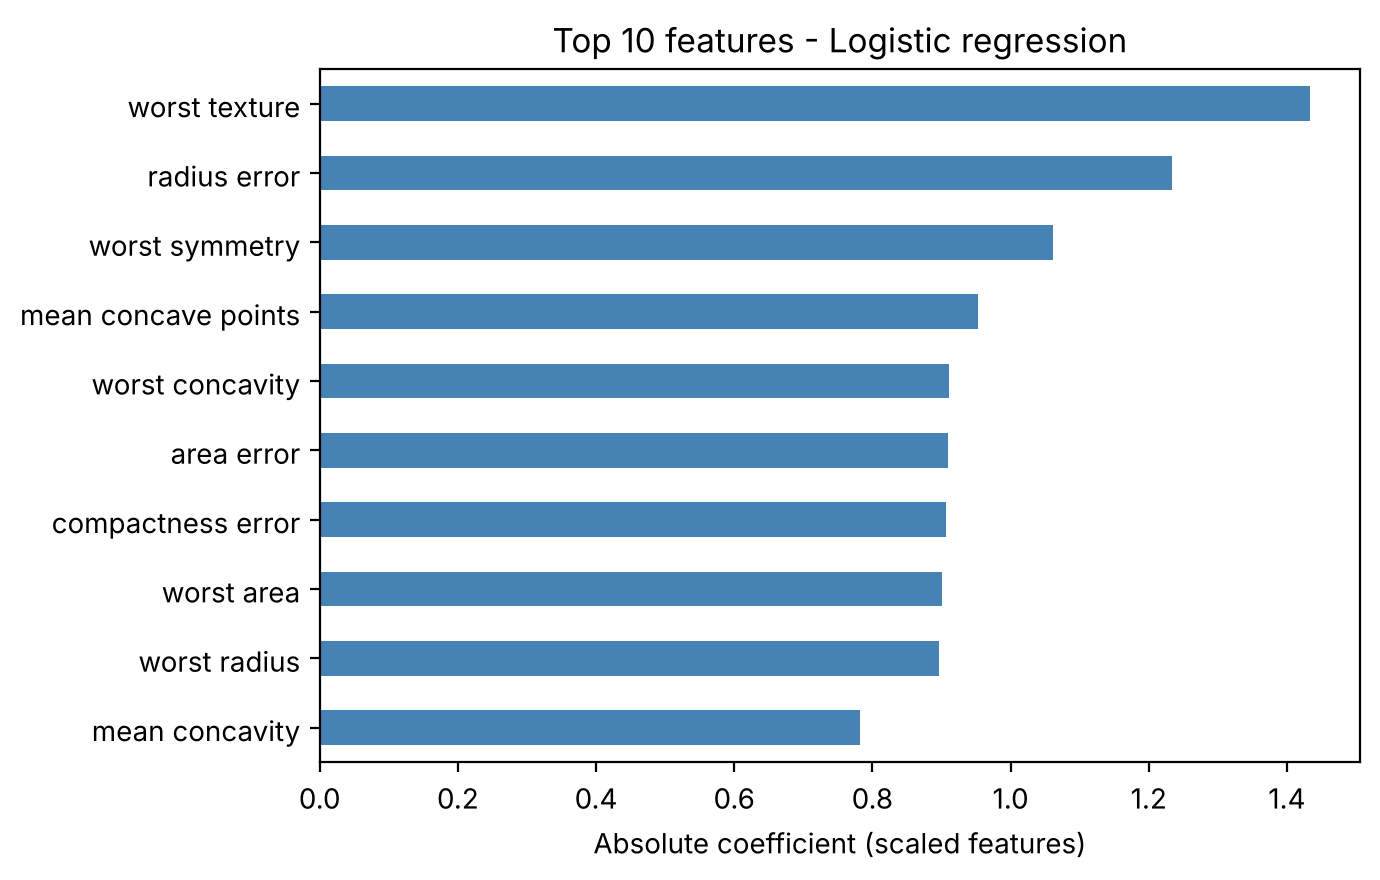

In [8]:
if best_name == "Logistic regression":
    coefs = final_model.named_steps["logisticregression"].coef_[0]
    importance = pd.Series(np.abs(coefs), index=X.columns)
    label = "Absolute coefficient (scaled features)"
else:
    importance = pd.Series(final_model.feature_importances_, index=X.columns)
    label = "Feature importance"

top = importance.sort_values(ascending=False).head(10).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
top.plot.barh(ax=ax, color="steelblue")
ax.set_xlabel(label)
ax.set_title(f"Top 10 features - {best_name}")
plt.tight_layout()
plt.savefig("figures/top_features.png", dpi=150)
plt.show()

## 6. Limitations
- **Small, single dataset:** 569 samples from one source, with no external validation on data from other hospitals or imaging setups, so results may not generalise.
- **Small test set:** The test set has only 114 samples, so each error moves the metrics noticeably. The numbers are estimates with uncertainty, not exact performance.
- **Not a clinical tool:** This is a learning project. It uses pre-extracted image features, not raw images or patient data, and has not been validated for any medical use.
- **Limited tuning:** I used default or lightly chosen settings and compared only two models.
- **Features are already engineered:** The 30 measurements were computed by others, so this project does not cover image processing.

## 7. Next steps
Try hyperparameter tuning, compare more models, look at probability calibration and threshold choice (to trade precision against recall), and test on a separate breast cancer dataset.